# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help → Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [37]:
%load_ext autoreload
%autoreload 2
# these make it so that if you change the files you import you won't need to restart the Jupyter Notebook kernel

from analytic_formulation import OlengEquations, Q_

# --- Params ---
params = {
    'rd':      Q_(0.316, 'm'),
    'nP':      Q_(4000, 'rpm'),
    'a':       1.2,
    'b':       1.0,
    'c':       0.5,
    'PP':      Q_(100.0, 'kW'),
    'mv':      Q_(1500.0, 'kg'),
    'g':       Q_(9.81, 'm/s**2'),
    'fr':      0.015,                    # plain float, avoids pint friction
    'rho_a':   Q_(1.225, 'kg/m**3'),
    'CD':      0.30,                     # plain float
    'Af':      Q_(2.2, 'm**2'),
    'gamma_m': 1.05,                     # plain float
    'eta_T':   0.92,                     # plain float
    'eta_o':   0.38,
    'HL':      Q_(44e6, 'J/kg'),
}



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Calculations
There is a problem in the formulation (formula 12 in the study):

$$ P_i = \frac{1}{\eta_T} \left( m_v \cdot g \cdot f_r \cdot \frac{v(t)}{3.6} + 0.5 \cdot \rho_a \cdot C_D \cdot A_f \cdot \left\{ \frac{v(t)}{3.6} \right\}^3 + m_v \cdot \gamma_m \cdot a(t) \right) $$
Where, in the final element for inertia, there is a unit problem and the correct formula should be:
$$ P_i = \frac{1}{\eta_T} \left( m_v g f_r + 0.5 \rho_a C_D A_f v^2 + m_v \gamma_m a \right) \cdot v $$
In the previous equations we did not sum power but force for the inertia.
$$ \text{Units} = [Mass] \cdot [Acceleration] = \textcolor{red}{\text{Newtons}} \text{ (Force)}$$



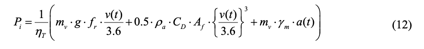

In [38]:
from scipy.optimize import minimize
from analytic_formulation import OlengEquations, Q_

delta_s    = Q_(500.0, 'm')
total_dist = Q_(5_000.0, 'm')
n_steps    = int(total_dist / delta_s)
v_cruise   = Q_(90, 'km/h').to('m/s')
v_initial = Q_(0.1, 'm/s')

# Use a dedicated model starting at cruise speed so the optimizer has a meaningful baseline
model_opt = OlengEquations(params, initial_velocity=v_initial)

initial_guess = [0.0 for _ in range(n_steps)]


def fuel_objective(acceleration_profile):
    results = model_opt.run(acceleration_profile, delta_s, xi_ax=3.9)

    total_fuel = results['fuel_cumulative_kg'].iloc[-1]

    return total_fuel


minimization = minimize(fuel_objective, initial_guess, method='Nelder-Mead')

print(fuel_objective(minimization.x))
print(minimization)


0.12142509924225932
       message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.12142509924225932
             x: [ 1.065e-02 -1.046e-02  8.262e-03 -8.102e-03  7.635e-03
                 -7.767e-03  1.014e-02 -1.036e-02  1.255e-02 -1.256e-02]
           nit: 1068
          nfev: 1515
 final_simplex: (array([[ 1.065e-02, -1.046e-02, ...,  1.255e-02,
                        -1.256e-02],
                       [ 1.060e-02, -1.041e-02, ...,  1.253e-02,
                        -1.254e-02],
                       ...,
                       [ 1.071e-02, -1.051e-02, ...,  1.251e-02,
                        -1.253e-02],
                       [ 1.063e-02, -1.044e-02, ...,  1.248e-02,
                        -1.250e-02]], shape=(11, 10)), array([ 1.214e-01,  1.214e-01,  1.214e-01,  1.214e-01,
                        1.214e-01,  1.214e-01,  1.214e-01,  1.214e-01,
                        1.214e-01,  1.214e-01,  1.214e-01]))


Optimal acceleration profile (m/s²):
[ 0.01064786 -0.0104557   0.00826228 -0.00810244  0.00763471 -0.00776705
  0.01013887 -0.01035627  0.01254726 -0.01256039]


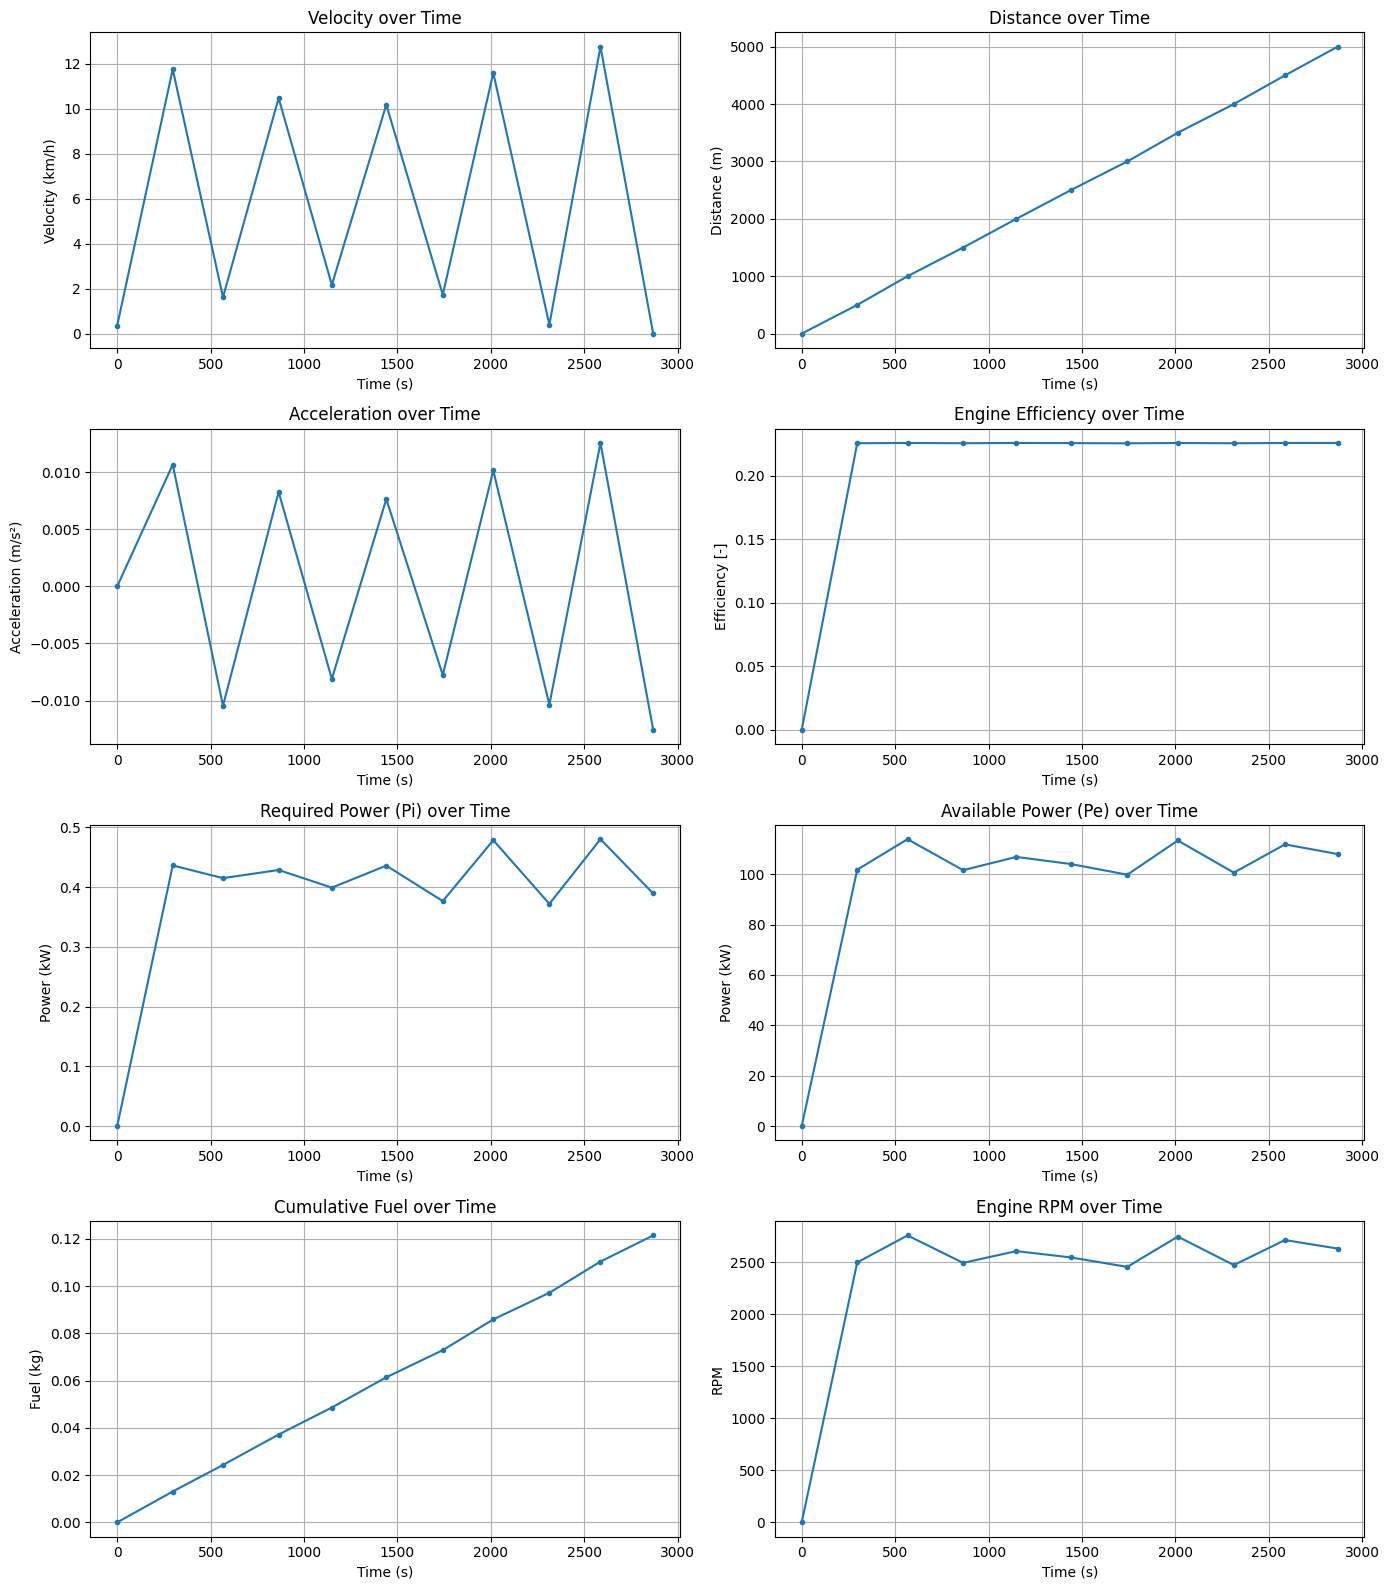

In [40]:
import matplotlib.pyplot as plt

results = model_opt.run(minimization.x, delta_s, xi_ax=3.9)

print("Optimal acceleration profile (m/s²):")
print(minimization.x)

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

plots = [
    ('time_s', 'velocity_ms',          'Time (s)', 'Velocity (km/h)',       'Velocity over Time'),
    ('time_s', 'distance_m',           'Time (s)', 'Distance (m)',          'Distance over Time'),
    ('time_s', 'acceleration_ms2',     'Time (s)', 'Acceleration (m/s²)',   'Acceleration over Time'),
    ('time_s', 'efficiency',           'Time (s)', 'Efficiency [-]',        'Engine Efficiency over Time'),
    ('time_s', 'Pi_kW',               'Time (s)', 'Power (kW)',            'Required Power (Pi) over Time'),
    ('time_s', 'Pe_kW',               'Time (s)', 'Power (kW)',            'Available Power (Pe) over Time'),
    ('time_s', 'fuel_cumulative_kg',   'Time (s)', 'Fuel (kg)',             'Cumulative Fuel over Time'),
    ('time_s', 'engine_rpm',           'Time (s)', 'RPM',                   'Engine RPM over Time'),
]

for ax, (x_col, y_col, x_label, y_label, title) in zip(axes, plots):
    y_data = results[y_col] * 3.6 if y_col == 'velocity_ms' else results[y_col]
    ax.plot(results[x_col], y_data, marker='o', markersize=3)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(True)

plt.tight_layout()
plt.show()